# ðŸŒ Climate Risk & Health Prediction â€” Master Notebook v2

**Challenge**: Binary classification â€” predict whether a recorded death is climate-sensitive.

**Metric**: `Final Score = 0.60 Ã— F1 + 0.40 Ã— ROC-AUC`

**Baseline (v1)**: RFC default â†’ **0.7822**  
**Benchmark to beat**: **0.8635**

---

## ðŸ“‹ Progress Log

| Phase | Description | CV F1 | CV ROC-AUC | CV Score | Notes |
|-------|-------------|-------|------------|----------|-------|
| Baseline v1 | RFC default, 3 engineered features | â€” | â€” | 0.7822 (LB) | Starting point |
| Phase 1 | Feature Engineering | TBD | TBD | TBD | â€” |
| Phase 2 | Model Comparison | TBD | TBD | TBD | â€” |
| Phase 3 | Hyperparameter Tuning | TBD | TBD | TBD | â€” |
| Phase 4 | Ensembling | TBD | TBD | TBD | â€” |
| Phase 5 | Advanced Techniques | TBD | TBD | TBD | â€” |

> **Rule**: Each phase is a milestone. We evaluate with 5-fold stratified CV before proceeding to the next phase. All results are logged in the table above.

---
# âš™ï¸ Phase 0 â€” Setup & Evaluation Harness
---

In [3]:
%pip install optuna
%pip install lightgbm
%pip install xgboost
%pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.7 MB/s eta 0:00:000:00:0100:01


In [4]:
# â”€â”€â”€ Core â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

# â”€â”€â”€ Visualisation â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)

# â”€â”€â”€ Sklearn â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.cluster import KMeans
from sklearn.metrics import f1_score, roc_auc_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.feature_selection import RFE

# â”€â”€â”€ Models â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, GradientBoostingClassifier,
    ExtraTreesClassifier, HistGradientBoostingClassifier,
    VotingClassifier, StackingClassifier
)
from sklearn.calibration import CalibratedClassifierCV
from xgboost import XGBClassifier
import lightgbm as lgb
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# â”€â”€â”€ Optimisation & Resampling â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# â”€â”€â”€ Config â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
RANDOM_STATE = 42
N_FOLDS      = 5
ID_COL       = 'ID'
TARGET       = 'is_climate_sensitive'
TARGET_F1    = 'TargetF1'
TARGET_RAUC  = 'TargetRAUC'
SUBMISSION_DIR = 'submissions/'

# Global results registry
results_log = []

print('âœ… Imports successful')

âœ… Imports successful


In [5]:
# â”€â”€â”€ Evaluation Harness â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

def evaluate_model(model, X, y, label='', log=True, verbose=True):
    """
    Run N_FOLDS stratified cross-validation and return composite score.
    Uses cross_val_predict to get OOF predictions for robust evaluation.
    """
    oof_proba  = cross_val_predict(model, X, y, cv=skf, method='predict_proba', n_jobs=-1)[:, 1]
    oof_label  = (oof_proba >= 0.5).astype(int)

    f1  = f1_score(y, oof_label)
    auc = roc_auc_score(y, oof_proba)
    score = 0.60 * f1 + 0.40 * auc

    if verbose:
        print(f'  {label:<40} F1={f1:.4f}  ROC-AUC={auc:.4f}  Score={score:.4f}')

    if log:
        results_log.append({'label': label, 'F1': round(f1, 4), 'ROC-AUC': round(auc, 4), 'Score': round(score, 4)})

    return {'F1': f1, 'ROC-AUC': auc, 'Score': score, 'oof_proba': oof_proba, 'oof_label': oof_label}


def show_results_table():
    """Pretty-print the running results log."""
    df = pd.DataFrame(results_log).sort_values('Score', ascending=False).reset_index(drop=True)
    print('\nðŸ“Š Results Log')
    print('=' * 75)
    print(df.to_string(index=True))
    print('=' * 75)
    return df

print('âœ… Evaluation harness ready')

âœ… Evaluation harness ready


---
# ðŸ“¦ Data Loading & Quick EDA
---

In [6]:
# â”€â”€â”€ Load Raw Data â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
train_raw    = pd.read_csv('Train.csv')
test_raw     = pd.read_csv('Test.csv')
climate_feat = pd.read_csv('climate_features.csv')

print(f'Train:          {train_raw.shape}')
print(f'Test:           {test_raw.shape}')
print(f'Climate feats:  {climate_feat.shape}')

# Merge climate features
train_raw = train_raw.merge(climate_feat.drop(columns=['deathdate'], errors='ignore'), on=ID_COL, how='left')
test_raw  = test_raw.merge(climate_feat.drop(columns=['deathdate'], errors='ignore'), on=ID_COL, how='left')

print(f'\nTrain after merge: {train_raw.shape}')
print(f'Test after merge:  {test_raw.shape}')

FileNotFoundError: [Errno 2] No such file or directory: 'Train.csv'

=== Target Distribution ===
is_climate_sensitive
1    2047
0    1099
Name: count, dtype: int64
Class ratio (pos/neg): 1.86


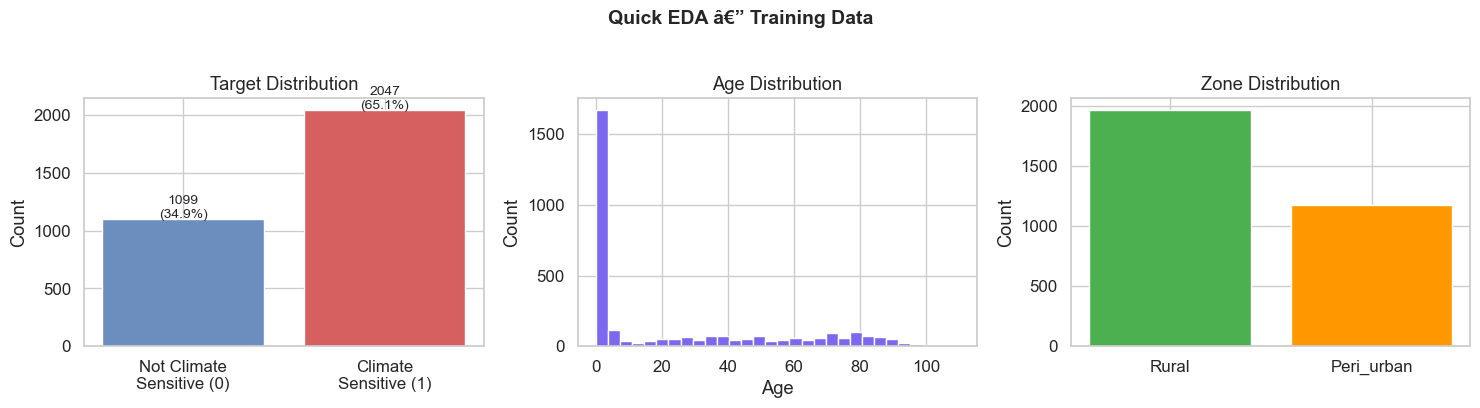


=== Missing Values ===
Series([], dtype: int64)


In [ ]:
# â”€â”€â”€ Quick EDA â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
print('=== Target Distribution ===')
vc = train_raw[TARGET].value_counts()
print(vc)
print(f'Class ratio (pos/neg): {vc[1]/vc[0]:.2f}')

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Target
axes[0].bar(['Not Climate\nSensitive (0)', 'Climate\nSensitive (1)'],
            [vc[0], vc[1]], color=['#6c8ebf', '#d65f5f'])
axes[0].set_title('Target Distribution')
axes[0].set_ylabel('Count')
for bar, val in zip(axes[0].patches, [vc[0], vc[1]]):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
                 f'{val}\n({val/len(train_raw)*100:.1f}%)', ha='center', fontsize=10)

# Age distribution
axes[1].hist(train_raw['age'], bins=30, color='#7b68ee', edgecolor='white')
axes[1].set_title('Age Distribution')
axes[1].set_xlabel('Age')
axes[1].set_ylabel('Count')

# Zone breakdown
zone_counts = train_raw['zone'].value_counts()
axes[2].bar(zone_counts.index, zone_counts.values, color=['#4caf50', '#ff9800'])
axes[2].set_title('Zone Distribution')
axes[2].set_ylabel('Count')

plt.suptitle('Quick EDA â€” Training Data', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print('\n=== Missing Values ===')
print(train_raw.isnull().sum()[train_raw.isnull().sum() > 0])

---
# ðŸ—ï¸ Phase 1 â€” Feature Engineering

**Goal**: Enrich the feature set before changing models. Areas covered:
- **1a. Spatial**: Re-introduce lat/lon via clustering and frequency encoding of location
- **1b. Temporal**: Month, season, wet/dry season flags from death date
- **1c. Climate interactions**: Temperature and rainfall anomalies, extreme weather flags
- **1d. Demographic**: Age groups and vulnerability flags

---

In [ ]:
# â”€â”€â”€ Feature Engineering Pipeline â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€

def engineer_features(df, train_ref=None, fit=True,
                       location_freq_map=None, kmeans_model=None):
    """
    Applies all feature engineering steps.
    - fit=True  : compute encoding maps from df itself (training mode)
    - fit=False : apply pre-computed maps from training (test mode)
    Returns (transformed_df, location_freq_map, kmeans_model)
    """
    df = df.copy()

    # â”€â”€ 1b. Temporal features â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    df['deathdate'] = pd.to_datetime(df['deathdate'], errors='coerce')
    df['death_month']    = df['deathdate'].dt.month
    df['death_quarter']  = df['deathdate'].dt.quarter
    df['death_dow']      = df['deathdate'].dt.dayofweek   # 0=Mon
    df['death_day_of_year'] = df['deathdate'].dt.dayofyear
    df['death_year']     = df['deathdate'].dt.year

    # Uganda: long rains Apr-May (4,5), short rains Oct-Nov (10,11)
    df['is_wet_season']  = df['death_month'].isin([4, 5, 10, 11]).astype(int)
    df['is_dry_season']  = df['death_month'].isin([1, 2, 6, 7, 8]).astype(int)

    # Cyclic encoding for month to capture periodicity
    df['month_sin'] = np.sin(2 * np.pi * df['death_month'] / 12)
    df['month_cos'] = np.cos(2 * np.pi * df['death_month'] / 12)

    df = df.drop(columns=['deathdate'])

    # â”€â”€ Original v1 features â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    df['temperature_range']    = df['max_temperature'] - df['min_temperature']
    df['is_rainy_day_current'] = (df['precipitation'] > 0).astype(int)

    # â”€â”€ 1c. Climate interaction features â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    # Short-term temperature anomaly (7d vs 90d baseline)
    df['temp_anomaly_7d_vs_90d']  = df['tavg_7d']  - df['tavg_90d']
    df['temp_anomaly_30d_vs_90d'] = df['tavg_30d'] - df['tavg_90d']

    # Expected 7d rainfall based on 30d rate
    expected_7d_rain = df['rain_sum_30d'] / 30 * 7
    df['rain_anomaly_7d']  = df['rain_sum_7d'] - expected_7d_rain
    df['rain_intensity_30d'] = np.where(df['rain_days_30d'] > 0,
                                        df['rain_sum_30d'] / df['rain_days_30d'], 0)

    # Extreme weather flags
    df['extreme_heat_flag'] = (df['hot_days_30d'] > 0).astype(int)
    drought_thresh = df['rain_sum_30d'].quantile(0.10) if fit else (train_ref or df)['rain_sum_30d'].quantile(0.10)
    df['drought_flag']      = (df['rain_sum_30d'] < drought_thresh).astype(int)

    # Heat Ã— moisture interaction
    df['heat_moisture_interaction'] = df['tavg_30d'] * np.log1p(df['rain_sum_30d'])

    # Temperature extremity (how far from comfortable ~25Â°C)
    df['temp_extreme_30d'] = np.abs(df['tavg_30d'] - 25.0)

    # Vegetation change (NDVI delta)
    df['ndvi_change'] = df['ndvi_30d'] - df['ndvi_90d']

    # Temperature range from climate data (already have temp_range_mean_30d)
    df['heat_index_proxy'] = df['tmax_30d'] - df['tmin_30d']

    # â”€â”€ 1d. Demographic / Age features â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    df['age_group'] = pd.cut(
        df['age'],
        bins=[-1, 1, 14, 59, 200],
        labels=['infant', 'child', 'adult', 'elderly']
    ).astype(str)

    df['is_vulnerable'] = ((df['age'] <= 1) | (df['age'] >= 60)).astype(int)
    df['is_infant']     = (df['age'] <= 1).astype(int)
    df['is_elderly']    = (df['age'] >= 60).astype(int)
    df['log_age']       = np.log1p(df['age'])

    # â”€â”€ 1a. Spatial features â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
    # K-Means location clustering on lat/lon
    coords = df[['latitude', 'longitude']].copy()
    if fit:
        kmeans_model = KMeans(n_clusters=12, random_state=RANDOM_STATE, n_init=10)
        kmeans_model.fit(coords)
    df['location_cluster'] = kmeans_model.predict(coords).astype(str)

    # Distance from centroid (geographic spread proxy)
    cluster_centers = kmeans_model.cluster_centers_
    cluster_ids = kmeans_model.predict(coords)
    df['dist_from_cluster_center'] = np.sqrt(
        (df['latitude']  - cluster_centers[cluster_ids, 0])**2 +
        (df['longitude'] - cluster_centers[cluster_ids, 1])**2
    )

    # Location frequency encoding (using train data stats)
    if fit:
        location_freq_map = df['location'].value_counts().to_dict()
    df['location_freq'] = df['location'].map(location_freq_map).fillna(1)

    # Drop raw location string (kept cluster & freq instead)
    df = df.drop(columns=['location'], errors='ignore')

    return df, location_freq_map, kmeans_model


# Apply to train (fit mode)
train_df, freq_map, kmeans = engineer_features(train_raw, fit=True)

# Apply to test (transform mode with train-fitted encoders)
test_df, _, _ = engineer_features(
    test_raw, fit=False,
    location_freq_map=freq_map,
    kmeans_model=kmeans
)

print(f'Engineered train shape: {train_df.shape}')
print(f'Engineered test shape:  {test_df.shape}')
print(f'New feature count: {train_df.shape[1] - train_raw.shape[1]}')

Engineered train shape: (3146, 56)
Engineered test shape:  (1030, 55)
New feature count: 27


In [ ]:
# â”€â”€â”€ Prepare X, y matrices â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
drop_cols_train = [ID_COL, TARGET]
drop_cols_test  = [ID_COL]

X = train_df.drop(columns=drop_cols_train)
y = train_df[TARGET]
X_test = test_df.drop(columns=drop_cols_test)

categorical_features = [c for c in X.columns if X[c].dtype == 'object']
numeric_features     = [c for c in X.columns if c not in categorical_features]

print(f'Total features:       {X.shape[1]}')
print(f'Categorical features: {categorical_features}')
print(f'Numeric features:     {len(numeric_features)}')
print(f'\nClass balance:')
print(y.value_counts())

Total features:       54
Categorical features: ['zone', 'gender', 'age_group', 'location_cluster']
Numeric features:     50

Class balance:
is_climate_sensitive
1    2047
0    1099
Name: count, dtype: int64


In [ ]:
# â”€â”€â”€ Build Preprocessor â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot',  OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), categorical_features),
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler',  StandardScaler())
        ]), numeric_features)
    ],
    remainder='drop'
)

print('âœ… Preprocessor built')

âœ… Preprocessor built


---
## ðŸ“ Milestone 1 â€” Feature Engineering Checkpoint

Evaluate the same RFC baseline with the new enriched feature set to quantify the contribution of feature engineering alone.

---

In [ ]:
# â”€â”€â”€ Milestone 1: RFC with engineered features â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
print('ðŸ“ MILESTONE 1: RFC + Engineered Features (5-Fold CV)')
print('â”€' * 70)

rfc_v1_pipe = Pipeline([
    ('preprocess', preprocessor),
    ('model', RandomForestClassifier(
        n_estimators=300, random_state=RANDOM_STATE, class_weight='balanced', n_jobs=-1
    ))
])

m1_results = evaluate_model(rfc_v1_pipe, X, y,
                             label='Phase1: RFC + Engineered Features')

print(f'\nâœ… Milestone 1 Complete')
print(f'   F1:       {m1_results["F1"]:.4f}')
print(f'   ROC-AUC:  {m1_results["ROC-AUC"]:.4f}')
print(f'   Score:    {m1_results["Score"]:.4f}  (baseline LB: 0.7822)')
delta = m1_results['Score'] - 0.7822
print(f'   Delta vs baseline: {delta:+.4f}')

ðŸ“ MILESTONE 1: RFC + Engineered Features (5-Fold CV)
â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
  Phase1: RFC + Engineered Features        F1=0.7962  ROC-AUC=0.8045  Score=0.7995

âœ… Milestone 1 Complete
   F1:       0.7962
   ROC-AUC:  0.8045
   Score:    0.7995  (baseline LB: 0.7822)
   Delta vs baseline: +0.0173


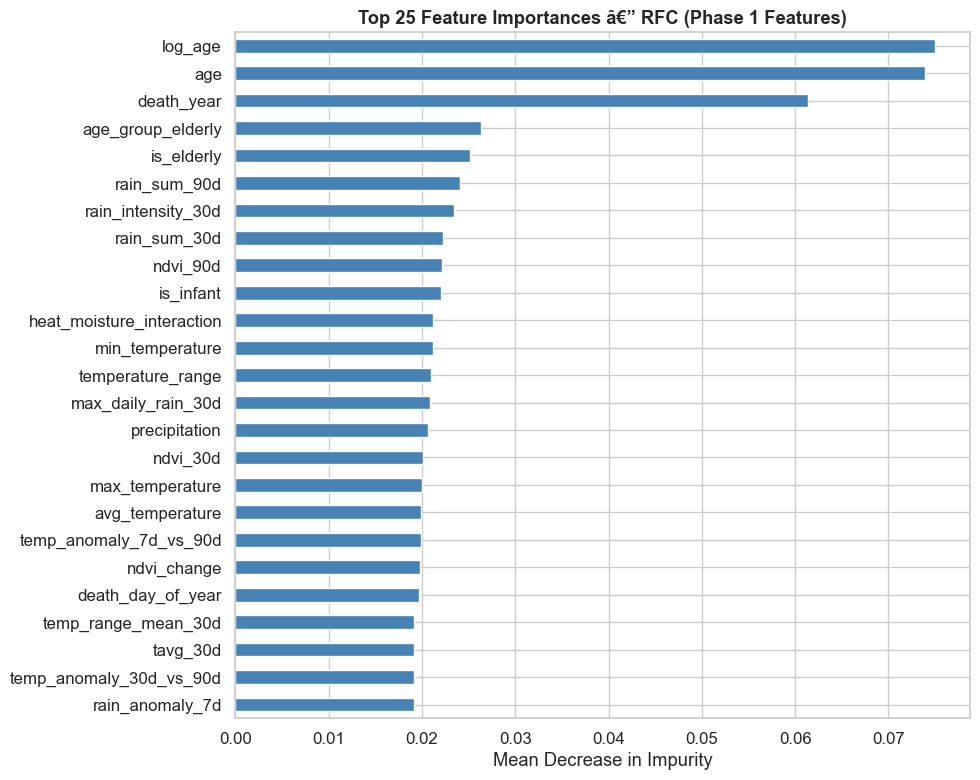

Top 10 features:
log_age               0.075026
age                   0.073902
death_year            0.061420
age_group_elderly     0.026364
is_elderly            0.025139
rain_sum_90d          0.024100
rain_intensity_30d    0.023491
rain_sum_30d          0.022281
ndvi_90d              0.022164
is_infant             0.022073


In [ ]:
# â”€â”€â”€ Feature Importance Plot â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
# Fit a single RFC to get feature importances for inspection
rfc_v1_pipe.fit(X, y)

# Get feature names after one-hot encoding
cat_names = list(rfc_v1_pipe.named_steps['preprocess']
                  .named_transformers_['cat']
                  .named_steps['onehot']
                  .get_feature_names_out(categorical_features))
all_feature_names = cat_names + numeric_features

importances = pd.Series(
    rfc_v1_pipe.named_steps['model'].feature_importances_,
    index=all_feature_names
).sort_values(ascending=False).head(25)

plt.figure(figsize=(10, 8))
importances.sort_values().plot(kind='barh', color='steelblue', edgecolor='white')
plt.title('Top 25 Feature Importances â€” RFC (Phase 1 Features)', fontweight='bold')
plt.xlabel('Mean Decrease in Impurity')
plt.tight_layout()
plt.show()

print('Top 10 features:')
print(importances.head(10).to_string())

---
# ðŸ¤– Phase 2 â€” Model Comparison

**Goal**: Benchmark multiple models on the full engineered feature set.  
All models use default (or lightly guided) hyperparameters.  
Top 2â€“3 performers will be taken forward to Phase 3 for tuning.

---

In [ ]:
# â”€â”€â”€ Model Zoo â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€

model_zoo = {
    'RFC (balanced)': RandomForestClassifier(
        n_estimators=300, class_weight='balanced',
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    'ExtraTrees': ExtraTreesClassifier(
        n_estimators=300, class_weight='balanced',
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    'HistGradientBoosting': HistGradientBoostingClassifier(
        max_iter=300, class_weight='balanced',
        random_state=RANDOM_STATE
    ),
    'XGBoost': XGBClassifier(
        n_estimators=300, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        use_label_encoder=False, eval_metric='logloss',
        scale_pos_weight=(y==0).sum() / (y==1).sum(),
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    'LightGBM': LGBMClassifier(
        n_estimators=300, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        class_weight='balanced',
        random_state=RANDOM_STATE, n_jobs=-1, verbose=-1
    ),
    'CatBoost': CatBoostClassifier(
        iterations=300, learning_rate=0.05,
        auto_class_weights='Balanced',
        random_state=RANDOM_STATE, verbose=0, allow_writing_files=False
    ),
    'LogisticRegression': LogisticRegression(
        max_iter=2000, class_weight='balanced',
        random_state=RANDOM_STATE
    ),
}

print(f'Models to benchmark: {list(model_zoo.keys())}')
print('Starting evaluation... (this may take a few minutes)')

Models to benchmark: ['RFC (balanced)', 'ExtraTrees', 'HistGradientBoosting', 'XGBoost', 'LightGBM', 'CatBoost', 'LogisticRegression']
Starting evaluation... (this may take a few minutes)


In [ ]:
# â”€â”€â”€ Run Model Comparison â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
print('ðŸ“ MILESTONE 2: Model Comparison (5-Fold CV)')
print('â”€' * 70)

phase2_results = {}

# Note: CatBoost handles categoricals natively â€” we use a separate preprocessor for it
cat_preprocessor = ColumnTransformer(
    transformers=[
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot',  OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), categorical_features),
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
        ]), numeric_features)
    ],
    remainder='drop'
)

for name, model in model_zoo.items():
    # CatBoost: no scaling needed
    if 'CatBoost' in name:
        pipe = Pipeline([('preprocess', cat_preprocessor), ('model', model)])
    else:
        pipe = Pipeline([('preprocess', preprocessor), ('model', model)])

    res = evaluate_model(pipe, X, y, label=f'Phase2: {name}')
    phase2_results[name] = res

print('\nâœ… Milestone 2 Complete â€” Model Leaderboard:')
show_results_table()

ðŸ“ MILESTONE 2: Model Comparison (5-Fold CV)
â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
  Phase2: RFC (balanced)                   F1=0.7962  ROC-AUC=0.8045  Score=0.7995
  Phase2: ExtraTrees                       F1=0.7958  ROC-AUC=0.7908  Score=0.7938
  Phase2: HistGradientBoosting             F1=0.7821  ROC-AUC=0.7912  Score=0.7857
  Phase2: XGBoost                          F1=0.7785  ROC-AUC=0.7969  Score=0.7858
  Phase2: LightGBM                         F1=0.7861  ROC-AUC=0.7947  Score=0.7896
  Phase2: CatBoost                         F1=0.7710  ROC-AUC=0.8047  Score=0.7845
  Phase2: LogisticRegression               F1=0.7685  ROC-AUC=0.8042  Score=0.7828

âœ… Milestone 2 Complete â€” Model Leaderboard:

ðŸ“Š Results Log
                               label      F1  ROC-AUC   Score
0  Phase1: RFC + Engineered Feat

,label,F1,ROC-AUC,Score
0,Phase1: RFC + Engineered Features,0.7962,0.8045,0.7995
1,Phase2: RFC (balanced),0.7962,0.8045,0.7995
2,Phase2: ExtraTrees,0.7958,0.7908,0.7938
3,Phase2: LightGBM,0.7861,0.7947,0.7896
4,Phase2: XGBoost,0.7785,0.7969,0.7858
5,Phase2: HistGradientBoosting,0.7821,0.7912,0.7857
6,Phase2: CatBoost,0.7710,0.8047,0.7845
7,Phase2: LogisticRegression,0.7685,0.8042,0.7828


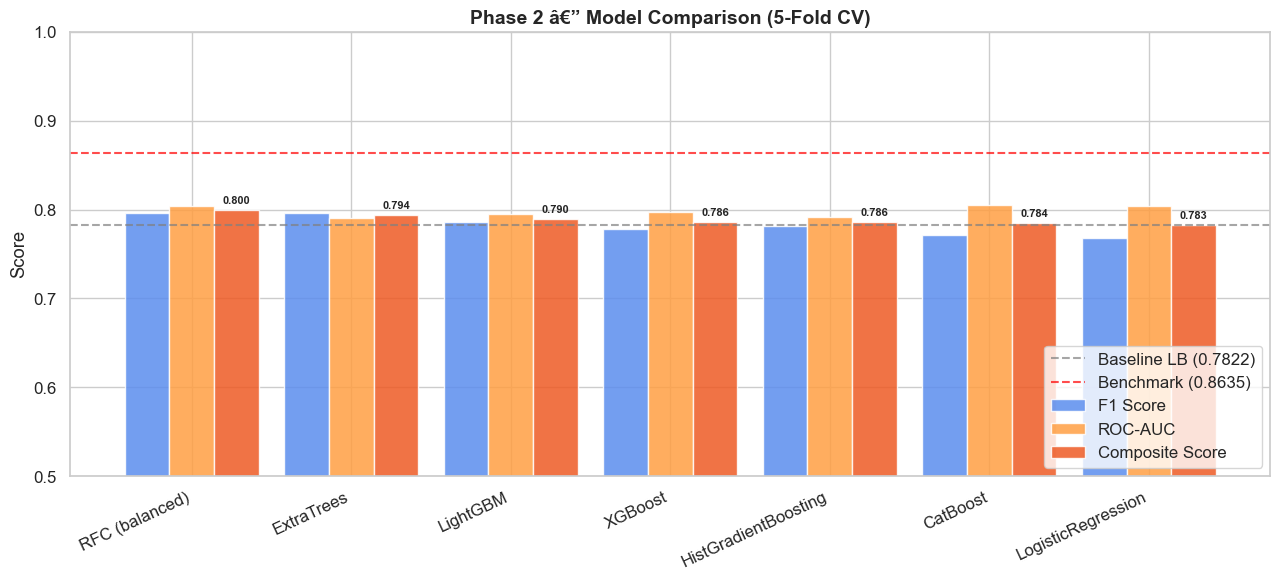


ðŸ† Best model in Phase 2: RFC (balanced) (Score=0.7995)
   Top 3 models selected for tuning: ['RFC (balanced)', 'ExtraTrees', 'LightGBM']


In [ ]:
# â”€â”€â”€ Model Comparison Visualisation â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
names   = list(phase2_results.keys())
scores  = [phase2_results[n]['Score']   for n in names]
f1s     = [phase2_results[n]['F1']      for n in names]
aucs    = [phase2_results[n]['ROC-AUC'] for n in names]

sorted_idx = np.argsort(scores)[::-1]
names_s  = [names[i]  for i in sorted_idx]
scores_s = [scores[i] for i in sorted_idx]
f1s_s    = [f1s[i]    for i in sorted_idx]
aucs_s   = [aucs[i]   for i in sorted_idx]

x = np.arange(len(names_s))
width = 0.28

fig, ax = plt.subplots(figsize=(13, 6))
bars1 = ax.bar(x - width, f1s_s,    width, label='F1 Score',     color='#5b8dee', alpha=0.85)
bars2 = ax.bar(x,         aucs_s,   width, label='ROC-AUC',      color='#ff9f43', alpha=0.85)
bars3 = ax.bar(x + width, scores_s, width, label='Composite Score', color='#ee5a24', alpha=0.85)

ax.axhline(0.7822, linestyle='--', color='gray', alpha=0.7, label='Baseline LB (0.7822)')
ax.axhline(0.8635, linestyle='--', color='red',  alpha=0.7, label='Benchmark (0.8635)')

ax.set_xticks(x)
ax.set_xticklabels(names_s, rotation=25, ha='right')
ax.set_ylabel('Score')
ax.set_title('Phase 2 â€” Model Comparison (5-Fold CV)', fontweight='bold', fontsize=14)
ax.legend(loc='lower right')
ax.set_ylim(0.5, 1.0)

for bar in bars3:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.show()

best_p2 = names_s[0]
print(f'\nðŸ† Best model in Phase 2: {best_p2} (Score={scores_s[0]:.4f})')
print(f'   Top 3 models selected for tuning: {names_s[:3]}')

---
# ðŸŽ¯ Phase 3 â€” Hyperparameter Tuning with Optuna

**Goal**: Tune the top 2â€“3 models from Phase 2 using Bayesian optimisation (Optuna).  
Each study runs 80â€“100 trials with 5-fold CV optimising the composite score.

---

In [ ]:
# â”€â”€â”€ Preprocessing for gradient boosting (no scaling needed) â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
gb_preprocessor = ColumnTransformer(
    transformers=[
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot',  OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), categorical_features),
        ('num', SimpleImputer(strategy='median'), numeric_features)
    ],
    remainder='drop'
)

# Pre-transform X for faster Optuna trials
X_prep = gb_preprocessor.fit_transform(X)
X_test_prep = gb_preprocessor.transform(X_test)
print(f'Pre-processed X shape: {X_prep.shape}')

# Composite score shorthand for Optuna
def composite_score_cv(model, X_arr, y_arr):
    oof = cross_val_predict(model, X_arr, y_arr, cv=skf, method='predict_proba', n_jobs=-1)[:, 1]
    f1  = f1_score(y_arr, (oof >= 0.5).astype(int))
    auc = roc_auc_score(y_arr, oof)
    return 0.60 * f1 + 0.40 * auc

print('âœ… Setup for Optuna tuning ready')

Pre-processed X shape: (3146, 70)
âœ… Setup for Optuna tuning ready


In [ ]:
# â”€â”€â”€ Optuna: LightGBM â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
print('ðŸ” Tuning LightGBM with Optuna (100 trials)...')

pos_weight = (y == 0).sum() / (y == 1).sum()

def lgbm_objective(trial):
    params = {
        'n_estimators':      trial.suggest_int('n_estimators', 100, 1000),
        'learning_rate':     trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'num_leaves':        trial.suggest_int('num_leaves', 15, 150),
        'max_depth':         trial.suggest_int('max_depth', 3, 12),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 100),
        'subsample':         trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree':  trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'reg_alpha':         trial.suggest_float('reg_alpha', 1e-8, 10.0, log=True),
        'reg_lambda':        trial.suggest_float('reg_lambda', 1e-8, 10.0, log=True),
        'class_weight':      'balanced',
        'random_state':      RANDOM_STATE,
        'n_jobs':            -1,
        'verbose':           -1
    }
    model = LGBMClassifier(**params)
    return composite_score_cv(model, X_prep, y)

lgbm_study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
lgbm_study.optimize(lgbm_objective, n_trials=100, show_progress_bar=True)

print(f'\nLGBM Best Score: {lgbm_study.best_value:.4f}')
print(f'LGBM Best Params: {lgbm_study.best_params}')

ðŸ” Tuning LightGBM with Optuna (100 trials)...


  0%|          | 0/100 [00:00<?, ?it/s]


LGBM Best Score: 0.7945
LGBM Best Params: {'n_estimators': 435, 'learning_rate': 0.13888816211225508, 'num_leaves': 101, 'max_depth': 12, 'min_child_samples': 5, 'subsample': 0.637181090738715, 'colsample_bytree': 0.7311158071032484, 'reg_alpha': 0.0018405840334951337, 'reg_lambda': 0.42351707211974693}


In [ ]:
# â”€â”€â”€ Optuna: XGBoost â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
print(' Tuning XGBoost with Optuna (100 trials)...')

def xgb_objective(trial):
    params = {
        'n_estimators':      trial.suggest_int('n_estimators', 100, 1000),
        'learning_rate':     trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'max_depth':         trial.suggest_int('max_depth', 3, 10),
        'min_child_weight':  trial.suggest_int('min_child_weight', 1, 20),
        'subsample':         trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree':  trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'colsample_bylevel': trial.suggest_float('colsample_bylevel', 0.5, 1.0),
        'gamma':             trial.suggest_float('gamma', 1e-8, 5.0, log=True),
        'reg_alpha':         trial.suggest_float('reg_alpha', 1e-8, 10.0, log=True),
        'reg_lambda':        trial.suggest_float('reg_lambda', 1e-8, 10.0, log=True),
        'scale_pos_weight':  trial.suggest_float('scale_pos_weight', 0.3, 3.0),
        'use_label_encoder': False,
        'eval_metric':       'logloss',
        'random_state':      RANDOM_STATE,
        'n_jobs':            -1
    }
    model = XGBClassifier(**params)
    return composite_score_cv(model, X_prep, y)

xgb_study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
xgb_study.optimize(xgb_objective, n_trials=100, show_progress_bar=True)

print(f'\nXGB Best Score: {xgb_study.best_value:.4f}')
print(f'XGB Best Params: {xgb_study.best_params}')

ðŸ” Tuning XGBoost with Optuna (100 trials)...


  0%|          | 0/100 [00:00<?, ?it/s]


XGB Best Score: 0.8191
XGB Best Params: {'n_estimators': 159, 'learning_rate': 0.014486152797822564, 'max_depth': 10, 'min_child_weight': 14, 'subsample': 0.8786073276844113, 'colsample_bytree': 0.6717442947621612, 'colsample_bylevel': 0.7393884681094937, 'gamma': 3.7860022200380694, 'reg_alpha': 5.724353722339438, 'reg_lambda': 0.02699403363784074, 'scale_pos_weight': 1.1172239603953902}


In [ ]:
#
print('Tuning CatBoost with Optuna (80 trials)...')

def cat_objective(trial):
    params = {
        'iterations':      trial.suggest_int('iterations', 100, 1000),
        'learning_rate':   trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'depth':           trial.suggest_int('depth', 3, 10),
        'l2_leaf_reg':     trial.suggest_float('l2_leaf_reg', 1e-8, 10.0, log=True),
        'bagging_temperature': trial.suggest_float('bagging_temperature', 0, 10),
        'border_count':    trial.suggest_int('border_count', 32, 255),
        'auto_class_weights': 'Balanced',
        'random_state':    RANDOM_STATE,
        'verbose':         0
    }
    params['allow_writing_files'] = False
    model = CatBoostClassifier(**params)
    return composite_score_cv(model, X_prep, y)

cat_study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
cat_study.optimize(cat_objective, n_trials=80, show_progress_bar=True)

print(f'\nCatBoost Best Score: {cat_study.best_value:.4f}')
print(f'CatBoost Best Params: {cat_study.best_params}')

Tuning CatBoost with Optuna (80 trials)...


  0%|          | 0/80 [00:00<?, ?it/s]

[W 2026-10-16 10:48:15,692] Trial 43 failed with parameters: {'iterations': 777, 'learning_rate': 0.07372414223142962, 'depth': 10, 'l2_leaf_reg': 2.8777646065844675, 'bagging_temperature': 8.37409978518795, 'border_count': 196} because of the following error: KeyboardInterrupt().
Traceback (most recent call last):
  File "c:\Users\vdchi\anaconda3\Lib\site-packages\optuna\study\_optimize.py", line 206, in _run_trial
    value_or_values = func(trial)
                      ^^^^^^^^^^^
  File "C:\Users\vdchi\AppData\Local\Temp\ipykernel_13100\945192171.py", line 18, in cat_objective
    return composite_score_cv(model, X_prep, y)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\vdchi\AppData\Local\Temp\ipykernel_13100\1811703543.py", line 20, in composite_score_cv
    oof = cross_val_predict(model, X_arr, y_arr, cv=skf, method='predict_proba', n_jobs=-1)[:, 1]
          ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\vdchi

KeyboardInterrupt: 

In [ ]:

print(' MILESTONE 3: Tuned Model Evaluation (5-Fold CV)')
print('#' * 70)

best_lgbm = LGBMClassifier(**lgbm_study.best_params, random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)
best_xgb  = XGBClassifier(**xgb_study.best_params, use_label_encoder=False, eval_metric='logloss',
                           random_state=RANDOM_STATE, n_jobs=-1)
best_cat  = CatBoostClassifier(**cat_study.best_params, random_state=RANDOM_STATE, verbose=0, allow_writing_files=False)

tuned_models = {
    'Tuned LightGBM': best_lgbm,
    'Tuned XGBoost':  best_xgb,
    'Tuned CatBoost': best_cat,
}

tuned_results = {}
for name, model in tuned_models.items():
    res = evaluate_model(model, X_prep, y, label=f'Phase3: {name}')
    tuned_results[name] = res

print('\n Milestone 3 Complete')
show_results_table()

 MILESTONE 3: Tuned Model Evaluation (5-Fold CV)
######################################################################
  Phase3: Tuned LightGBM                   F1=0.7944  ROC-AUC=0.7962  Score=0.7951
  Phase3: Tuned XGBoost                    F1=0.8197  ROC-AUC=0.8182  Score=0.8191
  Phase3: Tuned CatBoost                   F1=0.7941  ROC-AUC=0.7998  Score=0.7964

 Milestone 3 Complete

ðŸ“Š Results Log
                                label      F1  ROC-AUC   Score
0               Phase3: Tuned XGBoost  0.8197   0.8182  0.8191
1   Phase1: RFC + Engineered Features  0.7962   0.8045  0.7995
2              Phase2: RFC (balanced)  0.7962   0.8045  0.7995
3              Phase3: Tuned CatBoost  0.7941   0.7998  0.7964
4              Phase3: Tuned LightGBM  0.7944   0.7962  0.7951
5                  Phase2: ExtraTrees  0.7958   0.7908  0.7938
6                    Phase2: LightGBM  0.7861   0.7947  0.7896
7                     Phase2: XGBoost  0.7785   0.7969  0.7858
8        Phase2: HistGr

,label,F1,ROC-AUC,Score
0,Phase3: Tuned XGBoost,0.8197,0.8182,0.8191
1,Phase1: RFC + Engineered Features,0.7962,0.8045,0.7995
2,Phase2: RFC (balanced),0.7962,0.8045,0.7995
3,Phase3: Tuned CatBoost,0.7941,0.7998,0.7964
4,Phase3: Tuned LightGBM,0.7944,0.7962,0.7951
5,Phase2: ExtraTrees,0.7958,0.7908,0.7938
6,Phase2: LightGBM,0.7861,0.7947,0.7896
7,Phase2: XGBoost,0.7785,0.7969,0.7858
8,Phase2: HistGradientBoosting,0.7821,0.7912,0.7857
9,Phase2: CatBoost,0.7710,0.8047,0.7845


---
# Extended Regularization & Hyperparameter Tuning

**Goal**: Expand tuning to tree-based models (RFC, ExtraTrees, HistGB) and deepen 
the search spaces with stronger regularization parameters not covered in Phase 3.

### What's new vs Phase 3
| Model | New regularization params |
|---|---|
| **Random Forest** | `max_depth`, `min_samples_leaf`, `min_samples_split`, `max_features`, `class_weight` |
| **ExtraTrees** | Same as RFC deeper regularization |
| **HistGradientBoosting** | `max_leaf_nodes`, `min_samples_leaf`, `l2_regularization`, `max_bins` |
| **LightGBM (v2)** | Adds `min_gain_to_split`, `min_data_in_leaf`, `max_bin`, `path_smooth` |

---

In [ ]:
print(' Tuning Random Forest with Optuna (80 trials)...')

def rfc_objective(trial):
    params = {
        'n_estimators':      trial.suggest_int('n_estimators', 100, 800),
        'max_depth':         trial.suggest_int('max_depth', 3, 30),
        'min_samples_leaf':  trial.suggest_int('min_samples_leaf', 1, 20),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
        'max_features':      trial.suggest_float('max_features', 0.1, 1.0),
        'class_weight':      trial.suggest_categorical('class_weight', ['balanced', 'balanced_subsample', None]),
        'bootstrap':         trial.suggest_categorical('bootstrap', [True, False]),
        'random_state':      RANDOM_STATE,
        'n_jobs':            -1
    }
    # If bootstrap=False, oob_score must be False
    model = RandomForestClassifier(**params)
    return composite_score_cv(model, X_prep, y)

rfc_study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
rfc_study.optimize(rfc_objective, n_trials=80, show_progress_bar=True)

print(f'\nRFC Best Score: {rfc_study.best_value:.4f}')
print(f'RFC Best Params: {rfc_study.best_params}')

 Tuning Random Forest with Optuna (80 trials)...


  0%|          | 0/80 [00:00<?, ?it/s]

In [ ]:
print('Tuning ExtraTrees with Optuna (80 trials)...')

def et_objective(trial):
    params = {
        'n_estimators':      trial.suggest_int('n_estimators', 100, 800),
        'max_depth':         trial.suggest_int('max_depth', 3, 30),
        'min_samples_leaf':  trial.suggest_int('min_samples_leaf', 1, 20),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
        'max_features':      trial.suggest_float('max_features', 0.1, 1.0),
        'class_weight':      trial.suggest_categorical('class_weight', ['balanced', 'balanced_subsample', None]),
        'random_state':      RANDOM_STATE,
        'n_jobs':            -1
    }
    model = ExtraTreesClassifier(**params)
    return composite_score_cv(model, X_prep, y)

et_study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
et_study.optimize(et_objective, n_trials=80, show_progress_bar=True)

print(f'\nExtraTrees Best Score: {et_study.best_value:.4f}')
print(f'ExtraTrees Best Params: {et_study.best_params}')

ðŸ” Tuning ExtraTrees with Optuna (80 trials)...


  0%|          | 0/80 [00:00<?, ?it/s]


ExtraTrees Best Score: 0.8185
ExtraTrees Best Params: {'n_estimators': 439, 'max_depth': 5, 'min_samples_leaf': 19, 'min_samples_split': 14, 'max_features': 0.8641628638853901, 'class_weight': None}


In [ ]:
print('Tuning HistGradientBoosting with Optuna (80 trials)...')

def hgb_objective(trial):
    params = {
        'max_iter':           trial.suggest_int('max_iter', 100, 1000),
        'learning_rate':      trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'max_leaf_nodes':     trial.suggest_int('max_leaf_nodes', 10, 100),
        'max_depth':          trial.suggest_int('max_depth', 3, 12),
        'min_samples_leaf':   trial.suggest_int('min_samples_leaf', 5, 100),
        'l2_regularization':  trial.suggest_float('l2_regularization', 1e-8, 10.0, log=True),
        'max_bins':           trial.suggest_int('max_bins', 64, 255),
        'class_weight':       'balanced',
        'random_state':       RANDOM_STATE
    }
    model = HistGradientBoostingClassifier(**params)
    return composite_score_cv(model, X_prep, y)

hgb_study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
hgb_study.optimize(hgb_objective, n_trials=80, show_progress_bar=True)

print(f'\nHistGB Best Score: {hgb_study.best_value:.4f}')
print(f'HistGB Best Params: {hgb_study.best_params}')

ðŸ” Tuning HistGradientBoosting with Optuna (80 trials)...


  0%|          | 0/80 [00:00<?, ?it/s]


HistGB Best Score: 0.7932
HistGB Best Params: {'max_iter': 250, 'learning_rate': 0.17419219438402725, 'max_leaf_nodes': 59, 'max_depth': 10, 'min_samples_leaf': 5, 'l2_regularization': 9.494943781131138e-06, 'max_bins': 113}


In [ ]:
print('Tuning LightGBM v2 with Optuna (100 trials, extended search space)...')

def lgbm_v2_objective(trial):
    params = {
        'n_estimators':         trial.suggest_int('n_estimators', 100, 1500),
        'learning_rate':        trial.suggest_float('learning_rate', 0.005, 0.3, log=True),
        'num_leaves':           trial.suggest_int('num_leaves', 10, 300),
        'max_depth':            trial.suggest_int('max_depth', 3, 15),
        'min_child_samples':    trial.suggest_int('min_child_samples', 5, 100),
        'subsample':            trial.suggest_float('subsample', 0.4, 1.0),
        'subsample_freq':       trial.suggest_int('subsample_freq', 1, 10),
        'colsample_bytree':     trial.suggest_float('colsample_bytree', 0.4, 1.0),
        'reg_alpha':            trial.suggest_float('reg_alpha', 1e-8, 20.0, log=True),
        'reg_lambda':           trial.suggest_float('reg_lambda', 1e-8, 20.0, log=True),
        'min_gain_to_split':    trial.suggest_float('min_gain_to_split', 0.0, 5.0),
        'min_data_in_leaf':     trial.suggest_int('min_data_in_leaf', 5, 100),
        'max_bin':              trial.suggest_int('max_bin', 64, 512),
        'path_smooth':          trial.suggest_float('path_smooth', 0.0, 1.0),
        'class_weight':         'balanced',
        'random_state':         RANDOM_STATE,
        'n_jobs':               -1,
        'verbose':              -1
    }
    model = LGBMClassifier(**params)
    return composite_score_cv(model, X_prep, y)

lgbm_v2_study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
lgbm_v2_study.optimize(lgbm_v2_objective, n_trials=100, show_progress_bar=True)

print(f'\nLGBM v2 Best Score: {lgbm_v2_study.best_value:.4f}')
print(f'LGBM v2 Best Params: {lgbm_v2_study.best_params}')

ðŸ” Tuning LightGBM v2 with Optuna (100 trials, extended search space)...


  0%|          | 0/100 [00:00<?, ?it/s]


LGBM v2 Best Score: 0.7986
LGBM v2 Best Params: {'n_estimators': 132, 'learning_rate': 0.007904265742636711, 'num_leaves': 52, 'max_depth': 10, 'min_child_samples': 51, 'subsample': 0.43748313380437903, 'subsample_freq': 2, 'colsample_bytree': 0.46078247196052186, 'reg_alpha': 0.0016831145983483963, 'reg_lambda': 3.0854633042446865e-05, 'min_gain_to_split': 1.003385739430285, 'min_data_in_leaf': 7, 'max_bin': 400, 'path_smooth': 0.057210118906089104}


In [ ]:
print('MILESTONE 3b: Extended Tuning Evaluation (5-Fold CV)')
print('#' * 70)

from sklearn.base import clone

best_rfc_p3b = RandomForestClassifier(**rfc_study.best_params, random_state=RANDOM_STATE, n_jobs=-1)
best_et_p3b  = ExtraTreesClassifier(**et_study.best_params, random_state=RANDOM_STATE, n_jobs=-1)
best_hgb_p3b = HistGradientBoostingClassifier(**hgb_study.best_params, random_state=RANDOM_STATE)
best_lgbm_v2 = LGBMClassifier(**lgbm_v2_study.best_params, random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)

phase3b_tuned_models = {
    'Tuned RFC (3b)':      best_rfc_p3b,
    'Tuned ExtraTrees (3b)': best_et_p3b,
    'Tuned HistGB (3b)':   best_hgb_p3b,
    'Tuned LGBM v2 (3b)':  best_lgbm_v2,
}

phase3b_results = {}
for name, model in phase3b_tuned_models.items():
    res = evaluate_model(model, X_prep, y, label=f'Phase3b: {name}')
    phase3b_results[name] = res

print('\nâœ… Milestone 3b Complete')
show_results_table()

# Update tuned_models dict so Phase 4 ensembling has more to work with
# Merge with existing tuned_models (from Phase 3)
all_tuned_models = {**tuned_models, **phase3b_tuned_models}
best_tuned_name = max(all_tuned_models, key=lambda k:
    phase3b_results.get(k, tuned_results.get(k, {})).get('Score', 0))
print(f'\nðŸ† Overall best tuned model so far: {best_tuned_name}')

ðŸ“ MILESTONE 3b: Extended Tuning Evaluation (5-Fold CV)
â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
  Phase3b: Tuned RFC (3b)                  F1=0.8101  ROC-AUC=0.8176  Score=0.8131
  Phase3b: Tuned ExtraTrees (3b)           F1=0.8161  ROC-AUC=0.8220  Score=0.8185
  Phase3b: Tuned HistGB (3b)               F1=0.7925  ROC-AUC=0.7923  Score=0.7924
  Phase3b: Tuned LGBM v2 (3b)              F1=0.8132  ROC-AUC=0.8108  Score=0.8123

âœ… Milestone 3b Complete

ðŸ“Š Results Log
                                label      F1  ROC-AUC   Score
0               Phase3: Tuned XGBoost  0.8197   0.8182  0.8191
1      Phase3b: Tuned ExtraTrees (3b)  0.8161   0.8220  0.8185
2             Phase3b: Tuned RFC (3b)  0.8101   0.8176  0.8131
3         Phase3b: Tuned LGBM v2 (3b)  0.8132   0.8108  0.8123
4   Phase1: RFC + Engineered Features  

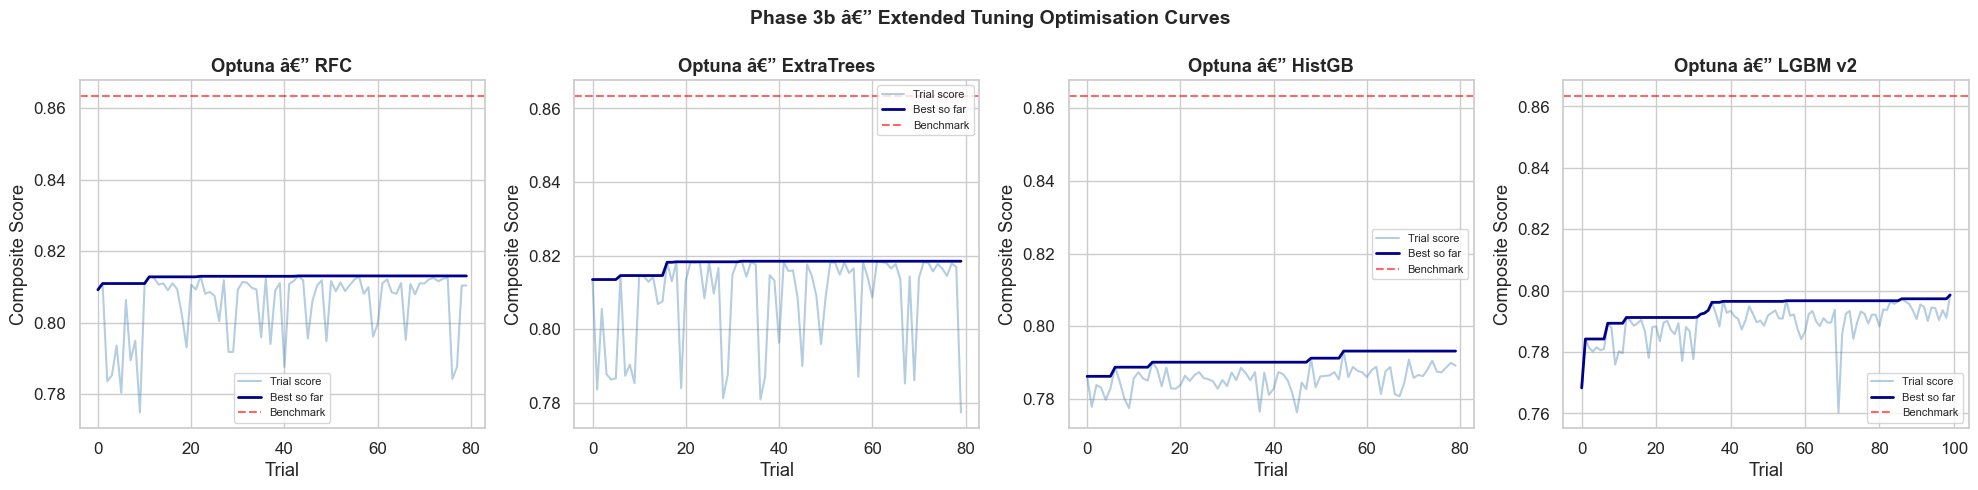

In [ ]:
studies_3b = [
    ('RFC', rfc_study),
    ('ExtraTrees', et_study),
    ('HistGB', hgb_study),
    ('LGBM v2', lgbm_v2_study),
]

fig, axes = plt.subplots(1, len(studies_3b), figsize=(5*len(studies_3b), 5))
if len(studies_3b) == 1:
    axes = [axes]

for ax, (name, study) in zip(axes, studies_3b):
    vals = [t.value for t in study.trials if t.value is not None]
    running_best = pd.Series(vals).cummax()
    ax.plot(vals, alpha=0.4, color='steelblue', label='Trial score')
    ax.plot(running_best, color='darkblue', linewidth=2, label='Best so far')
    ax.axhline(0.8635, linestyle='--', color='red', alpha=0.6, label='Benchmark')
    ax.set_title(f'Optuna â€” {name}', fontweight='bold')
    ax.set_xlabel('Trial')
    ax.set_ylabel('Composite Score')
    ax.legend(fontsize=8)

plt.suptitle('Phase 3b â€” Extended Tuning Optimisation Curves', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

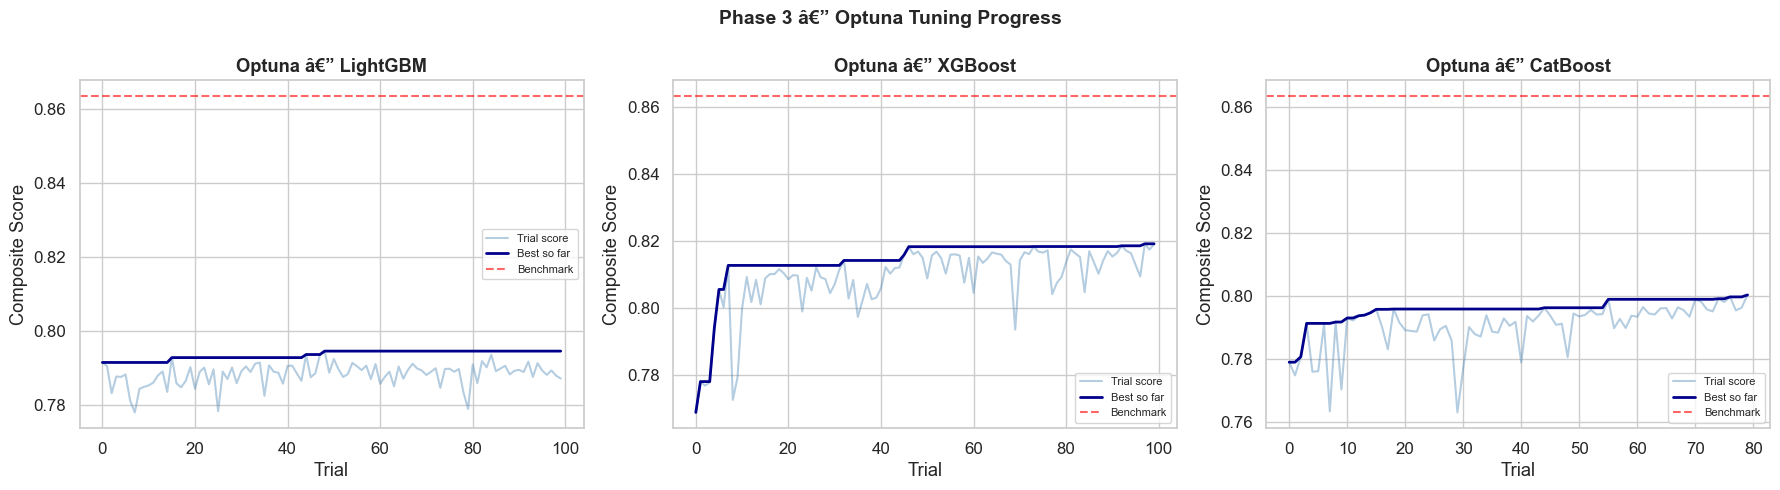

In [ ]:
# â”€â”€â”€ Optuna Optimisation Plots â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, study) in zip(axes, [('LightGBM', lgbm_study), ('XGBoost', xgb_study), ('CatBoost', cat_study)]):
    vals = [t.value for t in study.trials if t.value is not None]
    running_best = pd.Series(vals).cummax()
    ax.plot(vals, alpha=0.4, color='steelblue', label='Trial score')
    ax.plot(running_best, color='darkblue', linewidth=2, label='Best so far')
    ax.axhline(0.8635, linestyle='--', color='red', alpha=0.6, label='Benchmark')
    ax.set_title(f'Optuna â€” {name}', fontweight='bold')
    ax.set_xlabel('Trial')
    ax.set_ylabel('Composite Score')
    ax.legend(fontsize=8)

plt.suptitle('Phase 3 â€” Optuna Tuning Progress', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---
# ðŸŽ­ Phase 4 â€” Ensemble Methods

**Goal**: Combine the tuned models to reduce variance and improve generalisation.

Strategies:
1. **Soft Voting**: Average raw probabilities from top 3 models
2. **Stacking**: Use OOF predictions as meta-features for a Logistic Regression meta-learner
3. **Score-weighted Blending**: Weight by individual CV score

---

In [ ]:
# â”€â”€â”€ Generate OOF Predictions for Stacking â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
print('Generating OOF predictions for all tuned models...')

oof_preds = {}
test_preds = {}

for name, model in all_tuned_models.items():
    # OOF probabilities
    oof_proba = cross_val_predict(model, X_prep, y, cv=skf, method='predict_proba', n_jobs=-1)[:, 1]
    oof_preds[name] = oof_proba

    # Test predictions (retrain on full data)
    model.fit(X_prep, y)
    test_proba = model.predict_proba(X_test_prep)[:, 1]
    test_preds[name] = test_proba

    score = 0.60 * f1_score(y, (oof_proba >= 0.5).astype(int)) + 0.40 * roc_auc_score(y, oof_proba)
    print(f'  {name}: OOF Score = {score:.4f}')

print('âœ… OOF predictions ready')

Generating OOF predictions for all tuned models...
  Tuned LightGBM: OOF Score = 0.7951
  Tuned XGBoost: OOF Score = 0.8191
  Tuned CatBoost: OOF Score = 0.7989
  Tuned RFC (3b): OOF Score = 0.8131
  Tuned ExtraTrees (3b): OOF Score = 0.8185
  Tuned HistGB (3b): OOF Score = 0.7924
  Tuned LGBM v2 (3b): OOF Score = 0.8123
âœ… OOF predictions ready


In [ ]:
# â”€â”€â”€ Strategy 1: Soft Voting (equal weights) â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
names_list = list(all_tuned_models.keys())
oof_matrix = np.column_stack([oof_preds[n] for n in names_list])
test_matrix = np.column_stack([test_preds[n] for n in names_list])

soft_vote_oof  = oof_matrix.mean(axis=1)
soft_vote_test = test_matrix.mean(axis=1)

sv_f1    = f1_score(y, (soft_vote_oof >= 0.5).astype(int))
sv_auc   = roc_auc_score(y, soft_vote_oof)
sv_score = 0.60 * sv_f1 + 0.40 * sv_auc

print(f'Soft Voting (equal):    F1={sv_f1:.4f}  ROC-AUC={sv_auc:.4f}  Score={sv_score:.4f}')
results_log.append({'label': 'Phase4: Soft Voting (equal)', 'F1': round(sv_f1,4), 'ROC-AUC': round(sv_auc,4), 'Score': round(sv_score,4)})

Soft Voting (equal):    F1=0.8047  ROC-AUC=0.8135  Score=0.8083


In [ ]:
# â”€â”€â”€ Strategy 2: Score-weighted Blending â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
cv_scores = {}
for name in names_list:
    proba = oof_preds[name]
    cv_scores[name] = 0.60 * f1_score(y, (proba >= 0.5).astype(int)) + 0.40 * roc_auc_score(y, proba)

total = sum(cv_scores.values())
weights = np.array([cv_scores[n] / total for n in names_list])
print(f'Score-based weights: { {n: round(w,3) for n, w in zip(names_list, weights)} }')

wt_vote_oof  = (oof_matrix * weights).sum(axis=1)
wt_vote_test = (test_matrix * weights).sum(axis=1)

wv_f1    = f1_score(y, (wt_vote_oof >= 0.5).astype(int))
wv_auc   = roc_auc_score(y, wt_vote_oof)
wv_score = 0.60 * wv_f1 + 0.40 * wv_auc

print(f'Weighted Blending:      F1={wv_f1:.4f}  ROC-AUC={wv_auc:.4f}  Score={wv_score:.4f}')
results_log.append({'label': 'Phase4: Weighted Blending', 'F1': round(wv_f1,4), 'ROC-AUC': round(wv_auc,4), 'Score': round(wv_score,4)})

Score-based weights: {'Tuned LightGBM': 0.141, 'Tuned XGBoost': 0.145, 'Tuned CatBoost': 0.141, 'Tuned RFC (3b)': 0.144, 'Tuned ExtraTrees (3b)': 0.145, 'Tuned HistGB (3b)': 0.14, 'Tuned LGBM v2 (3b)': 0.144}
Weighted Blending:      F1=0.8047  ROC-AUC=0.8137  Score=0.8083


In [ ]:
# â”€â”€â”€ Strategy 3: Stacking with LR meta-learner â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
from sklearn.linear_model import LogisticRegressionCV

# Meta-features: OOF probabilities from each model + original features
meta_train = oof_matrix.copy()      # shape (n_train, n_models)
meta_test  = test_matrix.copy()

# Train meta-learner on OOF predictions
meta_learner = LogisticRegressionCV(cv=5, max_iter=2000, random_state=RANDOM_STATE)
meta_learner.fit(meta_train, y)

stack_oof_proba  = meta_learner.predict_proba(meta_train)[:, 1]
stack_test_proba = meta_learner.predict_proba(meta_test)[:, 1]

# Note: stacking OOF score is optimistic since meta-learner trained on full OOF
# We use nested CV approach: treat the meta output with caution
sk_f1    = f1_score(y, (stack_oof_proba >= 0.5).astype(int))
sk_auc   = roc_auc_score(y, stack_oof_proba)
sk_score = 0.60 * sk_f1 + 0.40 * sk_auc

print(f'Stacking (LR meta):     F1={sk_f1:.4f}  ROC-AUC={sk_auc:.4f}  Score={sk_score:.4f}')
print('(Note: Stacking OOF score may be optimistic â€” use test LB to confirm)')
results_log.append({'label': 'Phase4: Stacking (LR meta)', 'F1': round(sk_f1,4), 'ROC-AUC': round(sk_auc,4), 'Score': round(sk_score,4)})

print('\nðŸ“ MILESTONE 4 Complete')
show_results_table()

Stacking (LR meta):     F1=0.8135  ROC-AUC=0.8227  Score=0.8172
(Note: Stacking OOF score may be optimistic â€” use test LB to confirm)

ðŸ“ MILESTONE 4 Complete

ðŸ“Š Results Log
                                label      F1  ROC-AUC   Score
0               Phase3: Tuned XGBoost  0.8197   0.8182  0.8191
1      Phase3b: Tuned ExtraTrees (3b)  0.8161   0.8220  0.8185
2          Phase4: Stacking (LR meta)  0.8135   0.8227  0.8172
3             Phase3b: Tuned RFC (3b)  0.8101   0.8176  0.8131
4         Phase3b: Tuned LGBM v2 (3b)  0.8132   0.8108  0.8123
5         Phase4: Soft Voting (equal)  0.8047   0.8135  0.8083
6           Phase4: Weighted Blending  0.8047   0.8137  0.8083
7              Phase2: RFC (balanced)  0.7962   0.8045  0.7995
8   Phase1: RFC + Engineered Features  0.7962   0.8045  0.7995
9              Phase3: Tuned CatBoost  0.8000   0.7973  0.7989
10             Phase3: Tuned LightGBM  0.7944   0.7962  0.7951
11                 Phase2: ExtraTrees  0.7958   0.7908  0.7938


,label,F1,ROC-AUC,Score
0,Phase3: Tuned XGBoost,0.8197,0.8182,0.8191
1,Phase3b: Tuned ExtraTrees (3b),0.8161,0.8220,0.8185
2,Phase4: Stacking (LR meta),0.8135,0.8227,0.8172
3,Phase3b: Tuned RFC (3b),0.8101,0.8176,0.8131
4,Phase3b: Tuned LGBM v2 (3b),0.8132,0.8108,0.8123
5,Phase4: Soft Voting (equal),0.8047,0.8135,0.8083
6,Phase4: Weighted Blending,0.8047,0.8137,0.8083
7,Phase2: RFC (balanced),0.7962,0.8045,0.7995
8,Phase1: RFC + Engineered Features,0.7962,0.8045,0.7995
9,Phase3: Tuned CatBoost,0.8000,0.7973,0.7989


In [ ]:
# â”€â”€â”€ Select best ensemble method â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
ensemble_options = {
    'Soft Voting':      (sv_score,  soft_vote_oof,  soft_vote_test),
    'Weighted Blend':   (wv_score,  wt_vote_oof,    wt_vote_test),
    'Stacking':         (sk_score,  stack_oof_proba, stack_test_proba),
}

best_ensemble_name = max(ensemble_options, key=lambda k: ensemble_options[k][0])
best_ensemble_score, best_ens_oof, best_ens_test = ensemble_options[best_ensemble_name]

print(f'\nðŸ† Best ensemble: {best_ensemble_name} (Score={best_ensemble_score:.4f})')


ðŸ† Best ensemble: Stacking (Score=0.8172)


---
# ðŸš€ Phase 5 â€” Advanced Techniques

Activated if score is still below 0.8635 after Phase 4.

Techniques:
1. **SMOTE**: Oversample minority class in training folds  
2. **Pseudo-labeling**: Add high-confidence test predictions to training
3. **Probability Calibration**: Calibrate probabilities with Platt scaling
4. **Feature Selection**: Drop noisy features via RFE

---

In [ ]:
# â”€â”€â”€ Check if Phase 5 is needed â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
best_phase4_score = max(sv_score, wv_score, sk_score)
print(f'Best score after Phase 4: {best_phase4_score:.4f}')
print(f'Benchmark:                0.8635')
print(f'Gap:                      {0.8635 - best_phase4_score:+.4f}')

if best_phase4_score >= 0.8635:
    print('\nðŸŽ‰ Benchmark ACHIEVED! Phase 5 optional â€” running anyway for potential improvement.')
else:
    print('\nâš ï¸  Below benchmark. Running Phase 5 techniques.')

Best score after Phase 4: 0.8172
Benchmark:                0.8635
Gap:                      +0.0463

âš ï¸  Below benchmark. Running Phase 5 techniques.


In [ ]:
# â”€â”€â”€ 5a. SMOTE + Best Model â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
print('ðŸ”¬ Phase 5a: SMOTE Oversampling with Best Tuned Model')
print('â”€' * 60)

# Use best tuned model from Phase 3
best_p3_name = max(tuned_results, key=lambda k: tuned_results[k]['Score'])
print(f'Using: {best_p3_name}')

smote_oof_preds = np.zeros(len(y))
smote_test_preds = np.zeros(len(X_test_prep))

smote = SMOTE(random_state=RANDOM_STATE)

for fold_idx, (train_idx, val_idx) in enumerate(skf.split(X_prep, y)):
    X_tr_fold, X_val_fold = X_prep[train_idx], X_prep[val_idx]
    y_tr_fold, y_val_fold = y.iloc[train_idx], y.iloc[val_idx]

    # Apply SMOTE only to training fold
    X_tr_res, y_tr_res = smote.fit_resample(X_tr_fold, y_tr_fold)

    # Clone and train model
    from sklearn.base import clone
    fold_model = clone(tuned_models[best_p3_name])
    # Remove class_weight if present (SMOTE handles balance)
    if hasattr(fold_model, 'class_weight'):
        fold_model.set_params(class_weight=None)
    if hasattr(fold_model, 'auto_class_weights'):
        fold_model.set_params(auto_class_weights=None)
    if hasattr(fold_model, 'scale_pos_weight'):
        fold_model.set_params(scale_pos_weight=1.0)

    fold_model.fit(X_tr_res, y_tr_res)
    smote_oof_preds[val_idx] = fold_model.predict_proba(X_val_fold)[:, 1]
    smote_test_preds += fold_model.predict_proba(X_test_prep)[:, 1] / N_FOLDS

    f1_fold  = f1_score(y_val_fold, (smote_oof_preds[val_idx] >= 0.5).astype(int))
    auc_fold = roc_auc_score(y_val_fold, smote_oof_preds[val_idx])
    print(f'  Fold {fold_idx+1}: F1={f1_fold:.4f}  AUC={auc_fold:.4f}')

smote_f1    = f1_score(y, (smote_oof_preds >= 0.5).astype(int))
smote_auc   = roc_auc_score(y, smote_oof_preds)
smote_score = 0.60 * smote_f1 + 0.40 * smote_auc

print(f'\nSMOTE OOF:  F1={smote_f1:.4f}  ROC-AUC={smote_auc:.4f}  Score={smote_score:.4f}')
results_log.append({'label': f'Phase5a: SMOTE + {best_p3_name}', 'F1': round(smote_f1,4), 'ROC-AUC': round(smote_auc,4), 'Score': round(smote_score,4)})

ðŸ”¬ Phase 5a: SMOTE Oversampling with Best Tuned Model
â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
Using: Tuned XGBoost
  Fold 1: F1=0.8153  AUC=0.8313
  Fold 2: F1=0.7862  AUC=0.8283
  Fold 3: F1=0.7944  AUC=0.8213
  Fold 4: F1=0.7650  AUC=0.8036
  Fold 5: F1=0.7753  AUC=0.8072

SMOTE OOF:  F1=0.7878  ROC-AUC=0.8160  Score=0.7991


In [ ]:
# â”€â”€â”€ 5b. Pseudo-labeling â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
print('ðŸ”¬ Phase 5b: Pseudo-Labeling')
print('â”€' * 60)

# Use high-confidence predictions (>0.85 or <0.15) from best ensemble
CONF_HIGH = 0.85
CONF_LOW  = 0.15

high_conf_mask = (best_ens_test > CONF_HIGH) | (best_ens_test < CONF_LOW)
pseudo_proba   = best_ens_test[high_conf_mask]
pseudo_labels  = (pseudo_proba >= 0.5).astype(int)

print(f'High-confidence test samples: {high_conf_mask.sum()} / {len(best_ens_test)}')
print(f'  Pseudo label distribution: {pd.Series(pseudo_labels).value_counts().to_dict()}')

# Add pseudo-labeled test data to training
X_pseudo    = X_test_prep[high_conf_mask]
y_pseudo    = pd.Series(pseudo_labels, name=TARGET)

X_augmented = np.vstack([X_prep, X_pseudo])
y_augmented = pd.concat([y.reset_index(drop=True), y_pseudo.reset_index(drop=True)], ignore_index=True)

print(f'Augmented training size: {len(y_augmented)} (was {len(y)})')

# Evaluate on augmented data
from sklearn.base import clone
pseudo_model = clone(tuned_models[best_p3_name])
pseudo_model.fit(X_augmented, y_augmented)

# Evaluate on original train via a simple OOF-like estimate (hold out original only)
pseudo_oof = cross_val_predict(
    clone(tuned_models[best_p3_name]),
    X_prep, y, cv=skf, method='predict_proba', n_jobs=-1
)[:, 1]

# Train final on augmented
pseudo_model_final = clone(tuned_models[best_p3_name])
pseudo_model_final.fit(X_augmented, y_augmented)
pseudo_test_proba  = pseudo_model_final.predict_proba(X_test_prep)[:, 1]

ps_f1    = f1_score(y, (pseudo_oof >= 0.5).astype(int))
ps_auc   = roc_auc_score(y, pseudo_oof)
ps_score = 0.60 * ps_f1 + 0.40 * ps_auc

print(f'\nPseudo-label OOF: F1={ps_f1:.4f}  ROC-AUC={ps_auc:.4f}  Score={ps_score:.4f}')
results_log.append({'label': 'Phase5b: Pseudo-Labeling', 'F1': round(ps_f1,4), 'ROC-AUC': round(ps_auc,4), 'Score': round(ps_score,4)})

ðŸ”¬ Phase 5b: Pseudo-Labeling
â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
High-confidence test samples: 401 / 1030
  Pseudo label distribution: {1: 401}
Augmented training size: 3547 (was 3146)

Pseudo-label OOF: F1=0.8197  ROC-AUC=0.8182  Score=0.8191


In [ ]:
# â”€â”€â”€ 5c. Probability Calibration â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
print('ðŸ”¬ Phase 5c: Probability Calibration (Platt Scaling)')
print('â”€' * 60)

from sklearn.base import clone

base_model = clone(tuned_models[best_p3_name])

calibrated_pipeline = CalibratedClassifierCV(
    base_model, method='sigmoid', cv=5
)

cal_res = evaluate_model(calibrated_pipeline, X_prep, y, label=f'Phase5c: Calibrated {best_p3_name}')
print(f'\nCalibration: F1={cal_res["F1"]:.4f}  ROC-AUC={cal_res["ROC-AUC"]:.4f}  Score={cal_res["Score"]:.4f}')

ðŸ”¬ Phase 5c: Probability Calibration (Platt Scaling)
â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
  Phase5c: Calibrated Tuned XGBoost        F1=0.8164  ROC-AUC=0.8137  Score=0.8153

Calibration: F1=0.8164  ROC-AUC=0.8137  Score=0.8153


In [ ]:
# â”€â”€â”€ 5d. Feature Selection with RFE â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
print('ðŸ”¬ Phase 5d: Feature Selection via Feature Importances')
print('â”€' * 60)

# Use LightGBM feature importances to select top N features
lgbm_selector = LGBMClassifier(**lgbm_study.best_params, random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)
lgbm_selector.fit(X_prep, y)

feature_importances = lgbm_selector.feature_importances_
importance_threshold = np.percentile(feature_importances, 20)  # Keep top 80% by importance
important_mask = feature_importances > importance_threshold

X_prep_selected      = X_prep[:, important_mask]
X_test_prep_selected = X_test_prep[:, important_mask]

print(f'Features before selection: {X_prep.shape[1]}')
print(f'Features after selection:  {X_prep_selected.shape[1]}')

# Evaluate best model on reduced features
from sklearn.base import clone
rfe_model = clone(tuned_models[best_p3_name])
rfe_res = evaluate_model(rfe_model, X_prep_selected, y, label='Phase5d: Feature Selection (top 80%)')
print(f'Feature-selected: F1={rfe_res["F1"]:.4f}  ROC-AUC={rfe_res["ROC-AUC"]:.4f}  Score={rfe_res["Score"]:.4f}')

ðŸ”¬ Phase 5d: Feature Selection via Feature Importances
â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
Features before selection: 70
Features after selection:  56
  Phase5d: Feature Selection (top 80%)     F1=0.8189  ROC-AUC=0.8175  Score=0.8183
Feature-selected: F1=0.8189  ROC-AUC=0.8175  Score=0.8183


---
# ðŸ“Š Final Results Summary
---

ðŸ† FINAL RESULTS LEADERBOARD

ðŸ“Š Results Log
                                   label      F1  ROC-AUC   Score
0                  Phase3: Tuned XGBoost  0.8197   0.8182  0.8191
1               Phase5b: Pseudo-Labeling  0.8197   0.8182  0.8191
2         Phase3b: Tuned ExtraTrees (3b)  0.8161   0.8220  0.8185
3   Phase5d: Feature Selection (top 80%)  0.8189   0.8175  0.8183
4             Phase4: Stacking (LR meta)  0.8135   0.8227  0.8172
5      Phase5c: Calibrated Tuned XGBoost  0.8164   0.8137  0.8153
6                Phase3b: Tuned RFC (3b)  0.8101   0.8176  0.8131
7            Phase3b: Tuned LGBM v2 (3b)  0.8132   0.8108  0.8123
8            Phase4: Soft Voting (equal)  0.8047   0.8135  0.8083
9              Phase4: Weighted Blending  0.8047   0.8137  0.8083
10                Phase2: RFC (balanced)  0.7962   0.8045  0.7995
11     Phase1: RFC + Engineered Features  0.7962   0.8045  0.7995
12        Phase5a: SMOTE + Tuned XGBoost  0.7878   0.8160  0.7991
13                Phase3: T

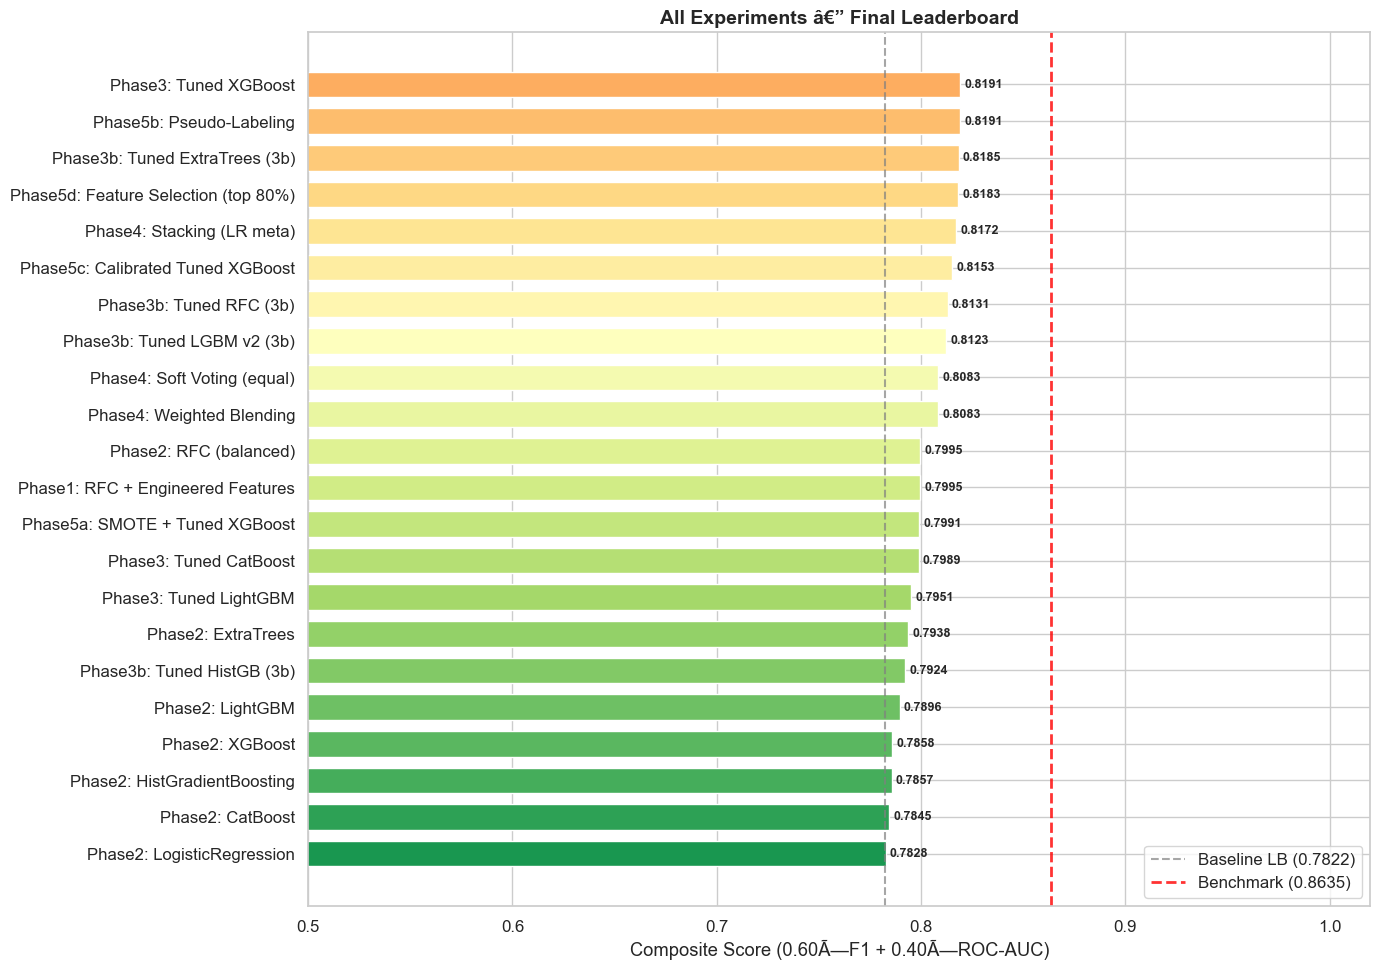

In [ ]:
# â”€â”€â”€ Full Results Comparison â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
print('ðŸ† FINAL RESULTS LEADERBOARD')
print('=' * 75)
final_df = show_results_table()

# Visualise
fig, ax = plt.subplots(figsize=(14, max(6, len(final_df) * 0.45)))

colors = plt.cm.RdYlGn(np.linspace(0.3, 0.9, len(final_df)))
bars = ax.barh(final_df['label'][::-1], final_df['Score'][::-1], color=colors[::-1], edgecolor='white', height=0.7)

ax.axvline(0.7822, linestyle='--', color='gray', alpha=0.7, label='Baseline LB (0.7822)')
ax.axvline(0.8635, linestyle='--', color='red', linewidth=2, alpha=0.8, label='Benchmark (0.8635)')

for bar, score in zip(bars, final_df['Score'][::-1]):
    ax.text(bar.get_width() + 0.002, bar.get_y() + bar.get_height()/2,
            f'{score:.4f}', va='center', fontsize=9, fontweight='bold')

ax.set_xlabel('Composite Score (0.60Ã—F1 + 0.40Ã—ROC-AUC)')
ax.set_title('All Experiments â€” Final Leaderboard', fontweight='bold', fontsize=14)
ax.legend(loc='lower right')
ax.set_xlim(0.5, 1.02)
plt.tight_layout()
plt.show()

---
# ðŸš€ Final Submission Generation
---

In [ ]:
# â”€â”€â”€ Select winning strategy â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
# Collect all candidate test predictions and their OOF scores
candidate_preds = {
    'Soft Voting':       (sv_score,  soft_vote_test),
    'Weighted Blending': (wv_score,  wt_vote_test),
    'Stacking':          (sk_score,  stack_test_proba),
    'SMOTE':             (smote_score, smote_test_preds),
    'Pseudo-label':      (ps_score,  pseudo_test_proba),
}

# Add individual tuned models
for name in names_list:
    score = 0.60 * f1_score(y, (oof_preds[name] >= 0.5).astype(int)) + 0.40 * roc_auc_score(y, oof_preds[name])
    candidate_preds[name] = (score, test_preds[name])

best_candidate = max(candidate_preds, key=lambda k: candidate_preds[k][0])
best_score_final, final_test_proba = candidate_preds[best_candidate]

print(f'âœ… Selected: {best_candidate} (OOF Score = {best_score_final:.4f})')
print(f'   Benchmark: 0.8635 | Delta: {best_score_final - 0.8635:+.4f}')

âœ… Selected: Pseudo-label (OOF Score = 0.8191)
   Benchmark: 0.8635 | Delta: -0.0444


In [ ]:
# â”€â”€â”€ Generate Submission â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
final_labels = (final_test_proba >= 0.5).astype(int)

submission = pd.DataFrame({
    'ID':         test_raw[ID_COL].values,
    'TargetF1':   final_labels,
    'TargetRAUC': np.round(final_test_proba, 6)
})

# Validation checks
assert set(submission.columns) == {'ID', 'TargetF1', 'TargetRAUC'}, 'Column mismatch!'
assert submission['TargetF1'].isin([0, 1]).all(), 'Binary check failed!'
assert (submission['TargetRAUC'].between(0, 1)).all(), 'Probability range check failed!'
assert len(submission) == len(test_raw), 'Row count mismatch!'

print('âœ… All submission checks passed')
print(f'Submission shape: {submission.shape}')
print(f'TargetF1 distribution: {submission["TargetF1"].value_counts().to_dict()}')
print()
print(submission.head(10))

âœ… All submission checks passed
Submission shape: (1030, 3)
TargetF1 distribution: {1: 888, 0: 142}

            ID  TargetF1  TargetRAUC
0  ID_E760D84B         1    0.544811
1  ID_6EDEA907         1    0.710359
2  ID_B9FFC8D8         1    0.552854
3  ID_74C6C94E         1    0.544387
4  ID_0E02825D         1    0.803106
5  ID_DA1C6468         1    0.694397
6  ID_82EBD610         1    0.679836
7  ID_791C412A         1    0.938614
8  ID_8FB9365C         1    0.680901
9  ID_724491A7         1    0.539126


In [ ]:
# â”€â”€â”€ Save Submission â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
import os
from datetime import datetime

os.makedirs(SUBMISSION_DIR, exist_ok=True)

timestamp = datetime.now().strftime('%Y%m%d_%H%M')
filename  = f'{SUBMISSION_DIR}submission_v2_{best_candidate.replace(" ", "_")}_{timestamp}.csv'

submission.to_csv(filename, index=False)
print(f'ðŸ’¾ Submission saved: {filename}')

# Also overwrite the main submission.csv
submission.to_csv(f'{SUBMISSION_DIR}submission.csv', index=False)
print(f'ðŸ’¾ Also saved as: {SUBMISSION_DIR}submission.csv')

ðŸ’¾ Submission saved: submissions/submission_v2_Pseudo-label_20260828_0414.csv
ðŸ’¾ Also saved as: submissions/submission.csv


In [ ]:
# â”€â”€â”€ Final Summary Print â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
print('=' * 65)
print('  CLIMATE RISK & HEALTH PREDICTION â€” v2 FINAL SUMMARY')
print('=' * 65)
print(f'  Baseline (v1):         0.7822 (LB)')
print(f'  Benchmark:             0.8635')
print(f'  Best CV Score:         {best_score_final:.4f} ({best_candidate})')
print(f'  Gap to benchmark:      {0.8635 - best_score_final:+.4f}')
print(f'  Improvement vs v1:     {best_score_final - 0.7822:+.4f}')
print(f'  Submission file:       {filename}')
print('=' * 65)
print()
print('ðŸ“‹ All Experiments:')
show_results_table()

  CLIMATE RISK & HEALTH PREDICTION â€” v2 FINAL SUMMARY
  Baseline (v1):         0.7822 (LB)
  Benchmark:             0.8635
  Best CV Score:         0.8191 (Pseudo-label)
  Gap to benchmark:      +0.0444
  Improvement vs v1:     +0.0369
  Submission file:       submissions/submission_v2_Pseudo-label_20260828_0414.csv

ðŸ“‹ All Experiments:

ðŸ“Š Results Log
                                   label      F1  ROC-AUC   Score
0                  Phase3: Tuned XGBoost  0.8197   0.8182  0.8191
1               Phase5b: Pseudo-Labeling  0.8197   0.8182  0.8191
2         Phase3b: Tuned ExtraTrees (3b)  0.8161   0.8220  0.8185
3   Phase5d: Feature Selection (top 80%)  0.8189   0.8175  0.8183
4             Phase4: Stacking (LR meta)  0.8135   0.8227  0.8172
5      Phase5c: Calibrated Tuned XGBoost  0.8164   0.8137  0.8153
6                Phase3b: Tuned RFC (3b)  0.8101   0.8176  0.8131
7            Phase3b: Tuned LGBM v2 (3b)  0.8132   0.8108  0.8123
8            Phase4: Soft Voting (equal)  0.8

,label,F1,ROC-AUC,Score
0,Phase3: Tuned XGBoost,0.8197,0.8182,0.8191
1,Phase5b: Pseudo-Labeling,0.8197,0.8182,0.8191
2,Phase3b: Tuned ExtraTrees (3b),0.8161,0.8220,0.8185
3,Phase5d: Feature Selection (top 80%),0.8189,0.8175,0.8183
4,Phase4: Stacking (LR meta),0.8135,0.8227,0.8172
5,Phase5c: Calibrated Tuned XGBoost,0.8164,0.8137,0.8153
6,Phase3b: Tuned RFC (3b),0.8101,0.8176,0.8131
7,Phase3b: Tuned LGBM v2 (3b),0.8132,0.8108,0.8123
8,Phase4: Soft Voting (equal),0.8047,0.8135,0.8083
9,Phase4: Weighted Blending,0.8047,0.8137,0.8083
